Homework 4

Q1. loading, cleaning, splitting and feature creation

Below is the feature-creation code from Homework 3, I included it because Part 2 needs it. It cleans the files that had problems (bending2/dataset4 is space-separated, cycling 9 and 14 have a trailing comma, and sitting/dataset8 is missing the row at t = 13500, which I filled by interpolation). Datasets 1–2 of bending1 and bending2 and 1–3 of the other folders are test data and the rest are train data (69 train, 19 test).

In [1]:
import re, glob, os, warnings, time
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.pipeline import Pipeline
import statsmodels.api as sm
from scipy.optimize import linprog
warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True)
RNG_SEED = 552
np.random.seed(RNG_SEED)

DATA_ROOT = '/Users/sharvari/Downloads/AReM'
assert os.path.isdir(DATA_ROOT), f'DATA_ROOT not found: {DATA_ROOT}'
print('folders found:', sorted(os.listdir(DATA_ROOT)))
COLS = ['time','avg_rss12','var_rss12','avg_rss13','var_rss13','avg_rss23','var_rss23']
SERIES = COLS[1:]
ACTIVITIES = ['bending1','bending2','cycling','lying','sitting','standing','walking']

def read_instance(path):
    rows = []
    for line in open(path).read().splitlines():
        if not line.strip() or line.startswith('#'):
            continue
        toks = [t for t in re.split(r'[,\s]+', line.strip()) if t]   
        rows.append([float(t) for t in toks[:7]])
    df = pd.DataFrame(rows, columns=COLS).set_index('time')
    if len(df) != 480:                                             
        df = df.reindex(np.arange(0, 480*250, 250)).interpolate(limit_direction='both')
    df = df.reset_index(drop=True)
    assert df.shape == (480, 6)
    return df

def load_all():
    inst = []
    for act in ACTIVITIES:
        files = sorted(glob.glob(f'{DATA_ROOT}/{act}/dataset*.csv'),
                       key=lambda p: int(re.findall(r'(\d+)', os.path.basename(p))[0]))
        for f in files:
            num = int(re.findall(r'(\d+)', os.path.basename(f))[0])
            limit = 2 if act in ('bending1','bending2') else 3
            inst.append(dict(activity=act, num=num, test=num <= limit, series=read_instance(f)))
    return inst

STATS = ['min','max','mean','median','std','q1','q3']
def stats_of(x):
    return [x.min(), x.max(), x.mean(), np.median(x), x.std(ddof=1), np.percentile(x,25), np.percentile(x,75)]

def feature_names(l=1):
    return [f'{st}{s+1}' + ('' if l == 1 else f'_p{part+1}')
            for part in range(l) for s in range(6) for st in STATS]

def extract(series_df, l=1):
    out = []
    for part in np.array_split(np.arange(len(series_df)), l):
        sub = series_df.iloc[part]
        for c in SERIES:
            out += stats_of(sub[c].values)
    return out

def build_X(instances, l=1):
    return pd.DataFrame([extract(i['series'], l) for i in instances], columns=feature_names(l))

folders found: ['.DS_Store', 'bending1', 'bending2', 'bendingType.pdf', 'cycling', 'lying', 'sensorsPlacement.pdf', 'sitting', 'standing', 'walking']


In [2]:
instances = load_all()
train = [i for i in instances if not i['test']]
test  = [i for i in instances if i['test']]
y_tr_act = np.array([i['activity'] for i in train]); y_te_act = np.array([i['activity'] for i in test])
y_tr = np.array([a.startswith('bending') for a in y_tr_act]).astype(int)   
y_te = np.array([a.startswith('bending') for a in y_te_act]).astype(int)
print(len(instances), len(train), len(test), y_tr.sum(), y_te.sum())

88 69 19 9 4


Q2.a(i).Scatter plots of feature from series 1,2 and 6

The three feature that I selected in homework 3 are mean, max and standard deviation

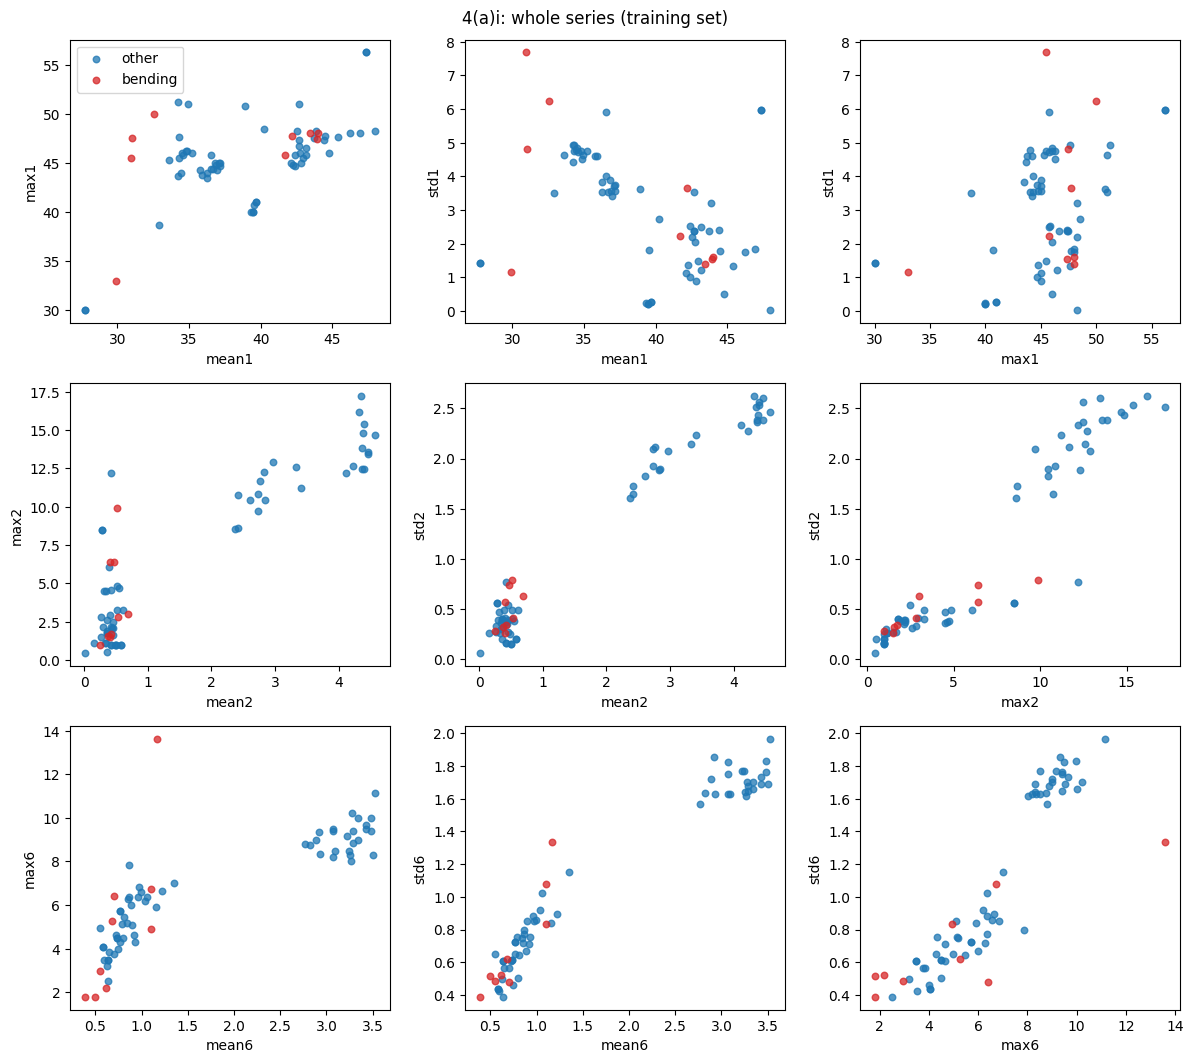

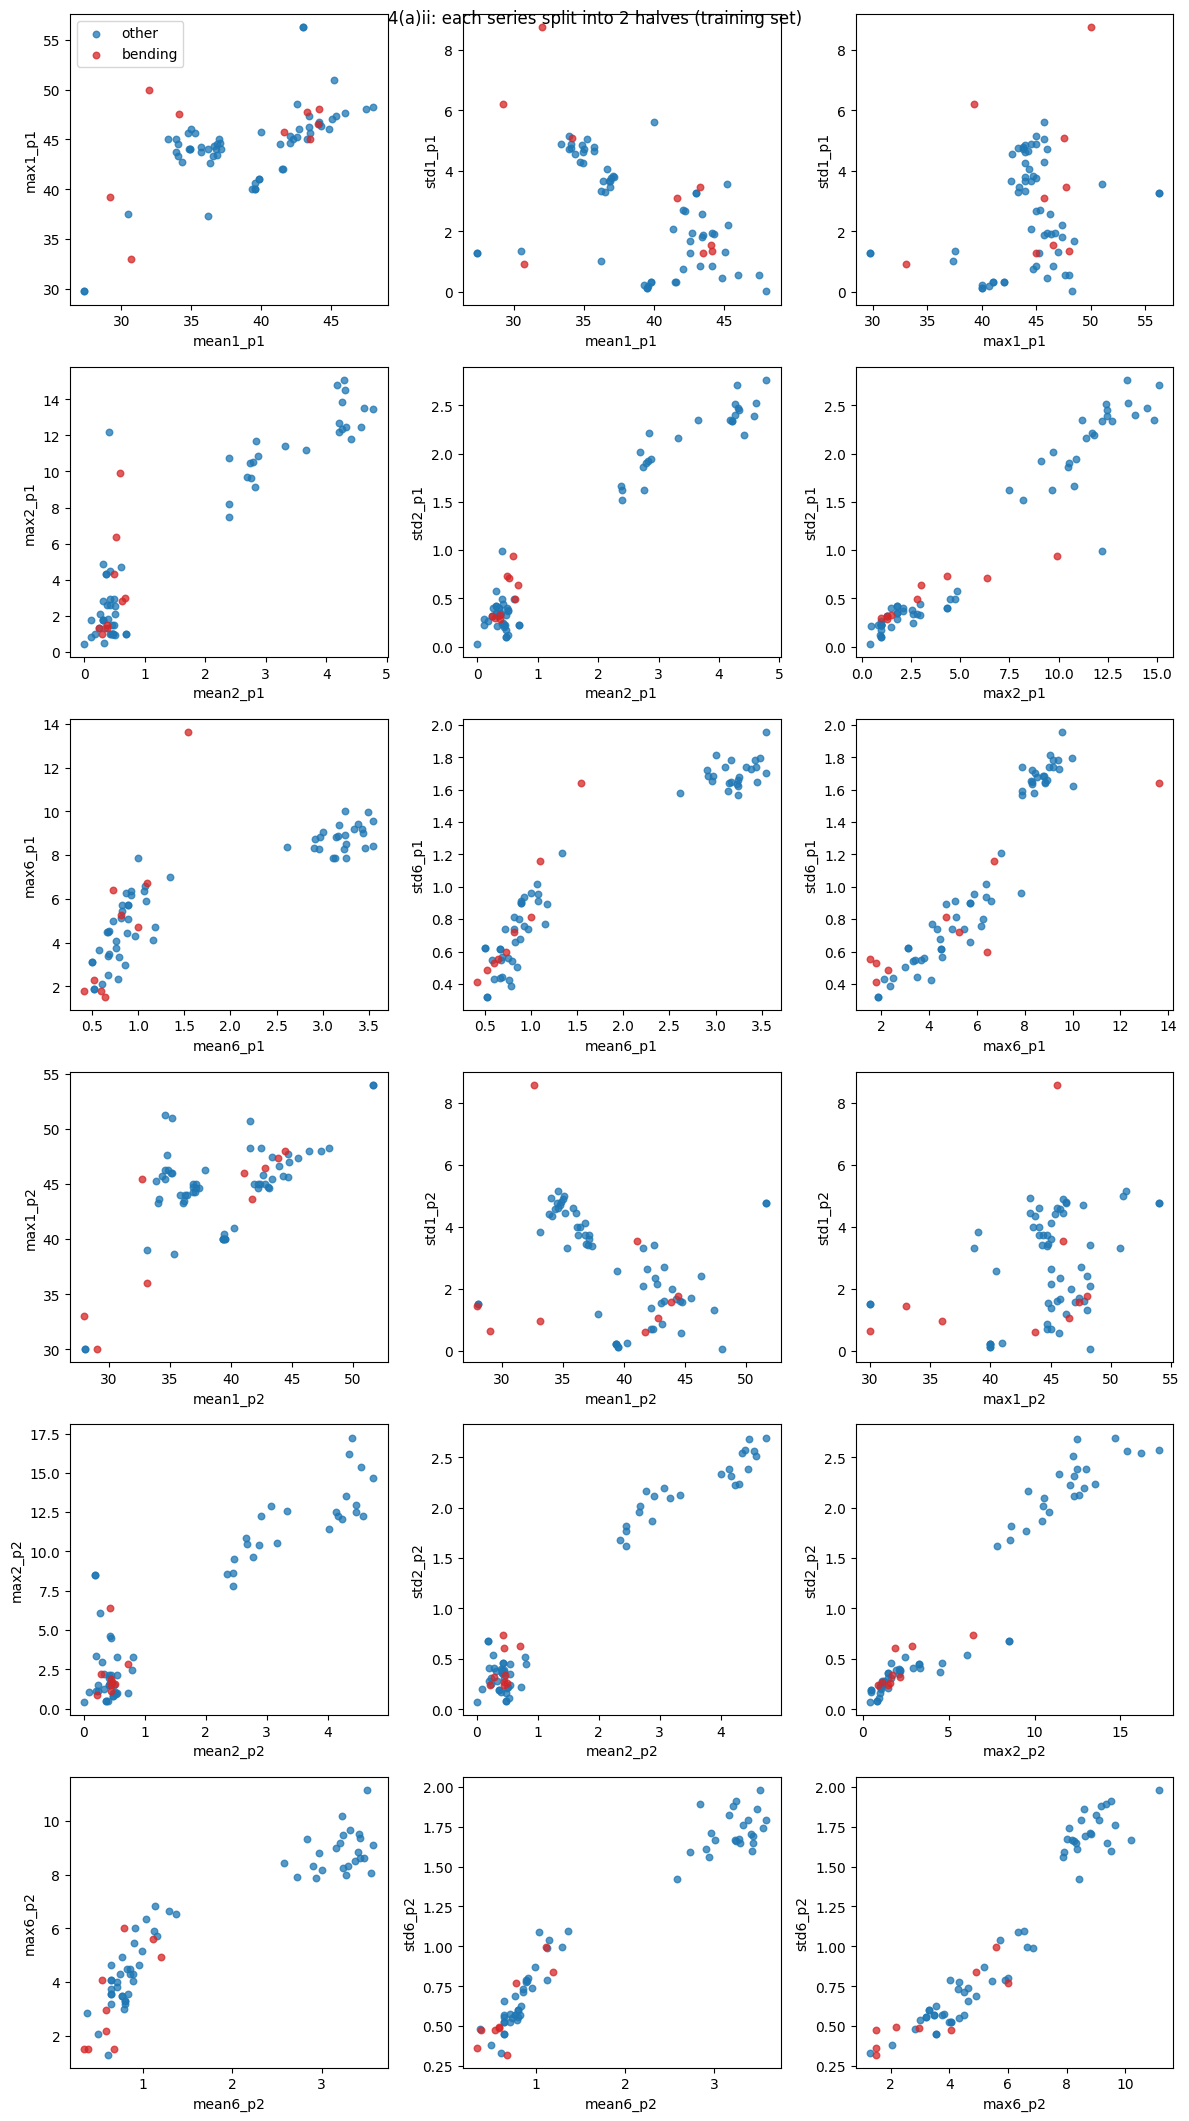

single-feature AUC (l=1):
 max1     0.649
mean1    0.570
std1     0.535
max2     0.634
mean2    0.628
std2     0.587
max6     0.698
mean6    0.772
std6     0.746

single-feature AUC (l=2):
 max1_p1     0.648
mean1_p1    0.533
std1_p1     0.594
max2_p1     0.600
mean2_p1    0.619
std2_p1     0.559
max6_p1     0.678
mean6_p1    0.735
std6_p1     0.698
max1_p2     0.564
mean1_p2    0.581
std1_p2     0.654
max2_p2     0.657
mean2_p2    0.656
std2_p2     0.643
max6_p2     0.790
mean6_p2    0.819
std6_p2     0.802


In [3]:
CHOSEN = ['mean', 'max', 'std']   

def scatter_grid(l, fname, title):
    Xl = build_X(train, l)
    parts = [''] if l == 1 else [f'_p{k+1}' for k in range(l)]
    pairs = [('mean', 'max'), ('mean', 'std'), ('max', 'std')]
    fig, axs = plt.subplots(3 * len(parts), 3, figsize=(12, 3.6 * 3 * len(parts)))
    axs = np.atleast_2d(axs); r = 0
    for pt in parts:
        for s in (1, 2, 6):
            for c, (a, b) in enumerate(pairs):
                ax = axs[r, c]
                for lab, col, nm in [(0, 'tab:blue', 'other'), (1, 'tab:red', 'bending')]:
                    ax.scatter(Xl[f'{a}{s}{pt}'][y_tr == lab], Xl[f'{b}{s}{pt}'][y_tr == lab], c=col, s=22, alpha=.75, label=nm)
                ax.set_xlabel(f'{a}{s}{pt}'); ax.set_ylabel(f'{b}{s}{pt}')
                if r == 0 and c == 0: ax.legend()
            r += 1
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=110); plt.show()
scatter_grid(1, 'figs/scatter_l1.png', '4(a)i: whole series (training set)')
scatter_grid(2, 'figs/scatter_l2.png', '4(a)ii: each series split into 2 halves (training set)')

def feat_auc(l):
    Xl = build_X(train, l); out = {}
    for c in Xl.columns:
        if any(c.startswith(f) and re.match(rf'{f}[126](_p\d)?$', c) for f in CHOSEN) and Xl[c].std() > 0:
            a = roc_auc_score(y_tr, Xl[c]); out[c] = max(a, 1 - a)
    return pd.Series(out)
print('single-feature AUC (l=1):\n', feat_auc(1).round(3).to_string()); print('\nsingle-feature AUC (l=2):\n', feat_auc(2).round(3).to_string())

Q2.a(ii). Splitting each series into two halves

Now every training instance has 12 series. The second figure shows both halves for series 1, 2 and 6 (the first three rows are the first half and the last three rows are the second half). Compared with the whole-series plots, the overlap for series 1 and 2 looks about the same. For series 6, the second half separates bending clearly better (single-feature AUCs of about 0.80–0.82 against 0.70–0.77 for the whole series), while the first half is slightly worse (about 0.68–0.74). So splitting shows when in the two minutes the bending activity looks different, which a summary of the whole series averages away. The price is twice as many features with only 69 training instances.

Q2.a(iii). Logistic regression with l = 1 to 20 and backward selection

How I set it up is, each of the 6 series is split into l parts of about equal length and the 7 statistics are computed on every part, so there are 42·l features. The number of instances does not change.
Logistic regression without L2 regularization (C = 1e6) and with max_iter = 200, which stops the optimizer early. This is needed because the classes turn out to be separable.
Backward selection is done with recursive feature elimination on the size of the standardized coefficients (it removes 20% of the remaining features per round while more than 40 remain, then one at a time). The p-values of the final model are shown further below.
(l, p) is chosen by stratified 5-fold cross-validation, where p is the number of features kept. Stratification is needed because only 13% of the instances are bending, so ordinary folds could end up with no positive instance. I repeated the 5-fold CV with 5 different shuffles and averaged the results, because one misclassified instance changes the accuracy by 1.4 points. If several pairs tie, I take the one with fewer features, and then the smaller l.
Right and wrong way to cross-validate. l and p are tuned, so the feature selection is part of the model. The right way is to do the scaling, the feature elimination and the fitting only on the training folds, and to use the held-out fold just for scoring. The wrong way is to select the features using all the training data and then cross-validate only the last fit. The held-out folds have then already influenced which features were kept, so the CV accuracy becomes too optimistic. 

In [4]:
BIG_C = 1e6          
MAX_ITER = 200       
def make_lr(**kw):
    return LogisticRegression(C=BIG_C, max_iter=MAX_ITER, **kw)

def backward_ranking(X, y, shrink=0.2, switch=40):
    
    d = X.shape[1]; remaining = list(range(d)); rank = np.zeros(d, dtype=int); r = d
    while len(remaining) > 1:
        m = make_lr().fit(X[:, remaining], y)
        imp = np.abs(m.coef_.ravel())
        k = 1 if len(remaining) <= switch else max(1, int(shrink * len(remaining)))
        k = min(k, len(remaining) - 1)
        drop = np.argsort(imp)[:k]
        for j in sorted(drop, reverse=True):
            rank[remaining[j]] = r; r -= 1; del remaining[j]
    rank[remaining[0]] = 1
    return rank

P_GRID = [1,2,3,4,5,6,7,8,9,10,12,15,20]
L_GRID = list(range(1, 21))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)

def cv_rfe_scores(train_inst, y, l, folds=skf):
   
    X = build_X(train_inst, l).values
    correct = {p: 0 for p in P_GRID if p <= X.shape[1]}
    for tr, va in folds.split(X, y):
        sc = StandardScaler().fit(X[tr]); Xt, Xv = sc.transform(X[tr]), sc.transform(X[va])
        rank = backward_ranking(Xt, y[tr])
        for p in correct:
            sel = rank <= p
            m = make_lr().fit(Xt[:, sel], y[tr])
            correct[p] += (m.predict(Xv[:, sel]) == y[va]).sum()
    return {p: c / len(y) for p, c in correct.items()}

N_REPEATS = 5     
t0 = time.time()
cv_table = {}
for l in L_GRID:
    accs = [cv_rfe_scores(train, y_tr, l, StratifiedKFold(5, shuffle=True, random_state=RNG_SEED + r))
            for r in range(N_REPEATS)]
    cv_table[l] = {p: np.mean([a[p] for a in accs]) for p in accs[0]}
print('CV time', round(time.time()-t0, 1), 's')
cv_df = pd.DataFrame(cv_table).T.rename_axis('l'); cv_df.columns.name = 'p'
print(cv_df.round(3).to_string())
best_acc = cv_df.max().max()
cands = [(p, l) for l in cv_df.index for p in cv_df.columns if abs(cv_df.loc[l, p] - best_acc) < 1e-12]
best_p, best_l = min(cands)      
print('best CV accuracy', round(best_acc, 4), 'ties:', sorted(cands)[:10], '-> chosen (l,p) =', (best_l, best_p))


CV time 48.3 s
p      1      2      3      4      5      6      7      8      9      10     12     15     20
l                                                                                            
1   0.930  0.928  0.939  0.954  0.971  0.965  0.948  0.959  0.957  0.957  0.965  0.971  0.968
2   0.907  0.942  0.945  0.928  0.942  0.936  0.942  0.942  0.936  0.933  0.933  0.942  0.939
3   0.954  0.922  0.930  0.942  0.945  0.936  0.930  0.933  0.936  0.933  0.936  0.942  0.939
4   0.948  0.913  0.904  0.913  0.925  0.928  0.916  0.928  0.945  0.930  0.945  0.945  0.945
5   0.922  0.913  0.922  0.913  0.925  0.916  0.925  0.913  0.922  0.933  0.919  0.919  0.925
6   0.930  0.925  0.930  0.933  0.945  0.939  0.939  0.945  0.951  0.951  0.939  0.930  0.939
7   0.916  0.904  0.916  0.913  0.925  0.936  0.933  0.936  0.933  0.925  0.928  0.919  0.916
8   0.910  0.907  0.899  0.907  0.901  0.896  0.922  0.916  0.922  0.925  0.928  0.916  0.916
9   0.907  0.910  0.922  0.933  0.930  0.922 

Q2.a(iv),(v) and (vi). Final model, training results, p-values and test set 

selected features (l=18, p=5): ['median5_p3', 'q15_p3', 'q31_p11', 'std6_p14', 'std5_p17']

statsmodels Logit on standardized selected features:
               beta       std_err    z  p_value
intercept  -39.8231  2.798781e+06 -0.0      1.0
median5_p3  16.2706  6.573083e+07  0.0      1.0
q15_p3      17.5772  7.590619e+07  0.0      1.0
q31_p11    -11.3620  7.674319e+06 -0.0      1.0
std6_p14   -11.9984  2.970441e+07 -0.0      1.0
std5_p17   -10.3758  1.222922e+06 -0.0      1.0

sklearn (C=1e6) coefficients: {'intercept': -13.0412, 'median5_p3': 5.0768, 'q15_p3': 5.9204, 'q31_p11': -5.7707, 'std6_p14': -3.1772, 'std5_p17': -4.9526}

Wald p-values are degenerate (huge standard errors): the classes are perfectly separable in this feature space, so p-value based pruning is not reliable here (it would discard every feature).
Logistic (RFE) - TRAIN: acc=1.0000 AUC=1.0000
  confusion [[TN FP],[FN TP]] =
[[60  0]
 [ 0  9]]
Logistic (RFE) - TEST: acc=0.8947 AUC=0.8500
  confusion [[TN FP],[FN TP

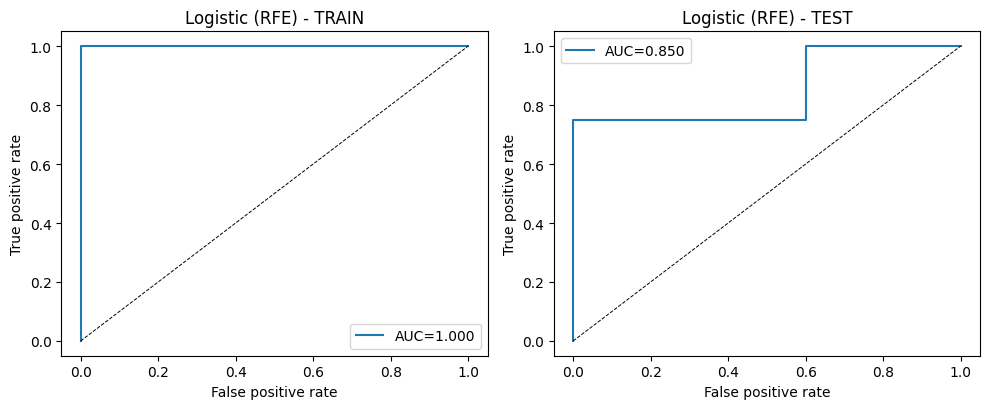

CV accuracy (best cell, repeated 5-fold) = 0.9739
WRONG-way CV acc at (l=18,p=5): 0.9768   vs right-way: 0.9739

Train set linearly separable in the selected 5-feature space? True
Train set linearly separable using ALL 756 features of l=18? True
class balance in train: bending=9, other=60 (13.0% positive)


In [5]:
def fit_final(train_inst, y, l, p):
    X = build_X(train_inst, l); names = list(X.columns)
    sc = StandardScaler().fit(X.values); Xs = sc.transform(X.values)
    rank = backward_ranking(Xs, y); sel = np.where(rank <= p)[0]
    model = make_lr().fit(Xs[:, sel], y)
    return dict(l=l, p=p, scaler=sc, sel=sel, names=[names[j] for j in sel], model=model)

def transform_for(fit, inst):
    X = build_X(inst, fit['l']).values
    return fit['scaler'].transform(X)[:, fit['sel']]

fit_lr = fit_final(train, y_tr, best_l, best_p)
Xtr_sel = transform_for(fit_lr, train); Xte_sel = transform_for(fit_lr, test)
print('selected features (l=%d, p=%d):' % (best_l, best_p), fit_lr['names'])

def logit_table(Xs, y, names):
    res = sm.Logit(y, sm.add_constant(Xs)).fit(disp=0, method='bfgs', maxiter=MAX_ITER)
    return pd.DataFrame({'beta': res.params, 'std_err': res.bse, 'z': res.tvalues, 'p_value': res.pvalues},
                        index=['intercept'] + names), res
tab_sm, res_sm = logit_table(Xtr_sel, y_tr, fit_lr['names'])
print('\nstatsmodels Logit on standardized selected features:'); print(tab_sm.round(4).to_string())
print('\nsklearn (C=1e6) coefficients:', dict(zip(['intercept'] + fit_lr['names'],
      np.r_[fit_lr['model'].intercept_, fit_lr['model'].coef_.ravel()].round(4))))


names_cur, X_cur = list(fit_lr['names']), Xtr_sel.copy()
pruned_ok = True
while True:
    tab_cur, _ = logit_table(X_cur, y_tr, names_cur)
    if (tab_cur['std_err'] > 1e3).any() or tab_cur['p_value'].isna().any():
        pruned_ok = False
        print('\nWald p-values are degenerate (huge standard errors): the classes are perfectly separable in this '
              'feature space, so p-value based pruning is not reliable here (it would discard every feature).')
        break
    pv = tab_cur['p_value'].drop('intercept')
    if pv.max() <= 0.05 or len(pv) == 1: break
    k = names_cur.index(pv.idxmax()); names_cur.pop(k); X_cur = np.delete(X_cur, k, axis=1)
if pruned_ok:
    print('\nAfter p-value pruning (alpha=0.05):'); print(tab_cur.round(4).to_string())


def evaluate(model, X, y, title, ax=None, thr=0.5, prob=None):
    prob = model.predict_proba(X)[:, 1] if prob is None else prob
    pred = (prob >= thr).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1]); auc = roc_auc_score(y, prob)
    print(f'{title}: acc={accuracy_score(y, pred):.4f} AUC={auc:.4f}\n  confusion [[TN FP],[FN TP]] =\n{cm}')
    fpr, tpr, _ = roc_curve(y, prob)
    if ax is not None:
        ax.plot(fpr, tpr, label=f'AUC={auc:.3f}'); ax.plot([0, 1], [0, 1], 'k--', lw=.7)
        ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title(title); ax.legend()
    return cm, auc, pred
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
cm_tr, auc_tr, _ = evaluate(fit_lr['model'], Xtr_sel, y_tr, 'Logistic (RFE) - TRAIN', axs[0])
cm_te, auc_te, _ = evaluate(fit_lr['model'], Xte_sel, y_te, 'Logistic (RFE) - TEST', axs[1])
plt.tight_layout(); plt.savefig('figs/roc_logistic.png', dpi=130); plt.show()
print('CV accuracy (best cell, repeated 5-fold) = %.4f' % best_acc)


def wrong_way_cv(l, p):
    X = StandardScaler().fit_transform(build_X(train, l).values)
    sel = backward_ranking(X, y_tr) <= p                     
    accs = []
    for r in range(N_REPEATS):
        c = 0
        for tr, va in StratifiedKFold(5, shuffle=True, random_state=RNG_SEED + r).split(X, y_tr):
            m = make_lr().fit(X[tr][:, sel], y_tr[tr]); c += (m.predict(X[va][:, sel]) == y_tr[va]).sum()
        accs.append(c / len(y_tr))
    return np.mean(accs)
print('WRONG-way CV acc at (l=%d,p=%d): %.4f   vs right-way: %.4f' %
      (best_l, best_p, wrong_way_cv(best_l, best_p), cv_df.loc[best_l, best_p]))


def linearly_separable(X, y):
    s = 2 * y - 1; n, d = X.shape
    A = -(s[:, None] * np.c_[X, np.ones(n)]); b = -np.ones(n)
    r = linprog(np.zeros(d + 1), A_ub=A, b_ub=b, bounds=[(None, None)] * (d + 1), method='highs')
    return r.status == 0
print('\nTrain set linearly separable in the selected %d-feature space? %s' % (best_p, linearly_separable(Xtr_sel, y_tr)))
Xall_l = StandardScaler().fit_transform(build_X(train, best_l).values)
print('Train set linearly separable using ALL %d features of l=%d? %s' % (Xall_l.shape[1], best_l, linearly_separable(Xall_l, y_tr)))
print('class balance in train: bending=%d, other=%d (%.1f%% positive)' % (y_tr.sum(), (1-y_tr).sum(), 100*y_tr.mean()))


The results are,

Training (iv): the confusion matrix is perfect and the AUC is 1. The coefficients are very large and their standard errors are huge, so all p-values are close to 1. That is a sign of perfect separation, not of useless features.

Test (v): the accuracy is 17/19 (89.5%) with an AUC of 0.85, below the cross-validated accuracy of about 97%. This is expected because (l, p) were tuned on the training data, and the test set has only 4 bending instances, so a single error changes the accuracy by about 5 points.

Separability (vi): a linear programming check says the training classes are linearly separable, even with just the 5 selected features. So the maximum likelihood estimate does not exist, the coefficients would keep growing without the iteration cap, and the p-values cannot be trusted. This is also why p-value pruning is not usable here, and why I used recursive feature elimination.

Q2.a(vii) Class imbalance and case control sampling

The training set has 9 bending and 60 other instances (13% and 87%), so yes, the classes are imbalanced. I built a case-control sample with all 9 cases and 9 randomly chosen controls (1:1), fitted the same logistic regression on the selected features, and corrected the intercept for the sampling: β0_adj = β0 + log(π/(1−π)) − log(π_s/(1−π_s)), where π = 0.13 is the prevalence in the training data and π_s = 0.5 is the prevalence in the sample. The slopes stay unchanged.

In [6]:
import sklearn
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import label_binarize
_NEW = tuple(int(v) for v in sklearn.__version__.split('.')[:2]) >= (1, 8)
def l1_lr(C, solver='liblinear', **kw):
   
    extra = dict(l1_ratio=1.0) if _NEW else dict(penalty='l1')
    kw.setdefault('max_iter', 5000)
    return LogisticRegression(C=C, solver=solver, **extra, **kw)

Imbalance: 9 positives vs 60 negatives (13.0% / 87.0%)
case-control coefficients (before adj): [-8.094  3.89   4.205 -4.343 -3.754 -2.243]
intercept shift = log(pi/(1-pi)) - log(pi_s/(1-pi_s)) = -1.8971 -> adjusted intercept -9.9909
--- case-control model (adjusted intercept)
Case-control - TRAIN: acc=1.0000 AUC=1.0000
  confusion [[TN FP],[FN TP]] =
[[60  0]
 [ 0  9]]
Case-control - TEST: acc=0.8947 AUC=0.9000
  confusion [[TN FP],[FN TP]] =
[[14  1]
 [ 1  3]]


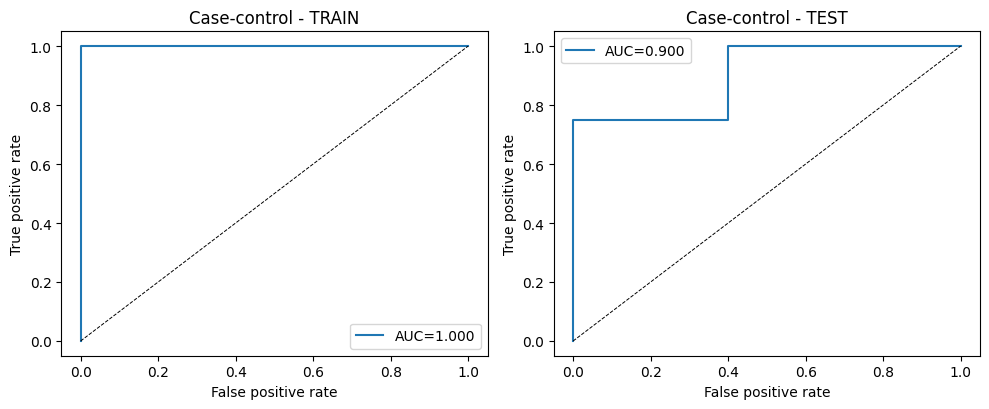

In [7]:
rng = np.random.default_rng(RNG_SEED)
pos, neg = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
print('Imbalance: %d positives vs %d negatives (%.1f%% / %.1f%%)' % (len(pos), len(neg), 100*len(pos)/len(y_tr), 100*len(neg)/len(y_tr)))
cc_idx = np.r_[pos, rng.choice(neg, size=len(pos), replace=False)]       
m_cc = make_lr().fit(Xtr_sel[cc_idx], y_tr[cc_idx])
pi, pi_s = y_tr.mean(), y_tr[cc_idx].mean()                              
shift = np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))                  
m_cc_adj = make_lr().fit(Xtr_sel[cc_idx], y_tr[cc_idx])
m_cc_adj.intercept_ = m_cc.intercept_ + shift
print('case-control coefficients (before adj):', np.r_[m_cc.intercept_, m_cc.coef_.ravel()].round(3))
print('intercept shift = log(pi/(1-pi)) - log(pi_s/(1-pi_s)) = %.4f -> adjusted intercept %.4f' % (shift, m_cc_adj.intercept_[0]))
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
print('--- case-control model (adjusted intercept)')
cm_cc_tr, auc_cc_tr, _ = evaluate(m_cc_adj, Xtr_sel, y_tr, 'Case-control - TRAIN', axs[0])
cm_cc_te, auc_cc_te, _ = evaluate(m_cc_adj, Xte_sel, y_te, 'Case-control - TEST', axs[1])
plt.tight_layout(); plt.savefig('figs/roc_case_control.png', dpi=130); plt.show()

Result. The confusion matrices are the same as before and the test AUC is 0.90 against 0.85. With only 18 sampled rows this is noisy, and the intercept correction matters more for the predicted probabilities and thresholds than for the ranking of the instances.

Q2.b(i) L1-penalized logistic regression

I standardize the features inside a pipeline and use liblinear. For each l from 1 to 20, C is chosen from 17 log-spaced values between 0.01 and 100 by repeated stratified 5-fold CV. The pair (l, C) with the highest CV accuracy is chosen, and ties go to the smaller l

L1 CV time 17.0 s
best L1 CV accuracy 0.9738 at l=12, C=1
1     0.968
2     0.957
3     0.968
4     0.954
5     0.931
6     0.939
7     0.951
8     0.931
9     0.925
10    0.942
11    0.965
12    0.974
13    0.948
14    0.945
15    0.922
16    0.928
17    0.936
18    0.959
19    0.960
20    0.968
non-zero coefficients: 8 of 504
median5_p2    0.3684
q15_p2        1.8347
max1_p7      -0.6725
std1_p7      -0.0404
q14_p9       -0.0414
q34_p9       -0.0909
min5_p11      0.5368
max6_p11     -0.2976
L1 logistic - TRAIN: acc=1.0000 AUC=1.0000
  confusion [[TN FP],[FN TP]] =
[[60  0]
 [ 0  9]]
L1 logistic - TEST: acc=0.9474 AUC=1.0000
  confusion [[TN FP],[FN TP]] =
[[15  0]
 [ 1  3]]


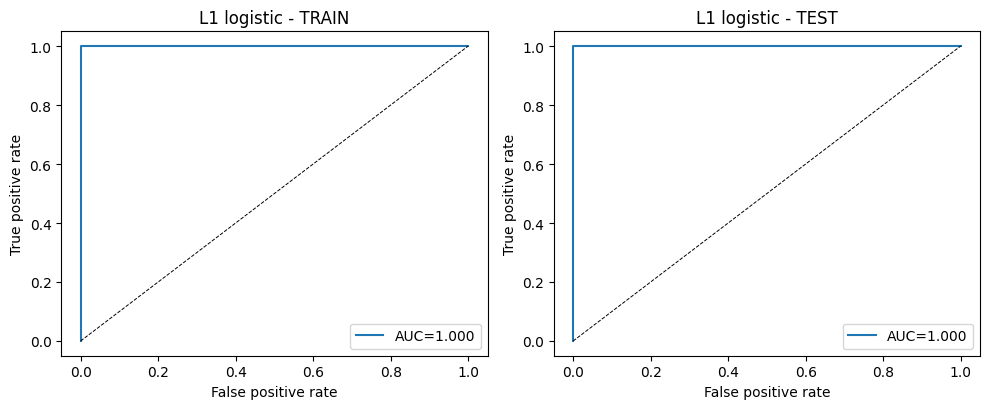

In [8]:
C_GRID = np.logspace(-2, 2, 17)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RNG_SEED)
l1_results = {}
t0 = time.time()
for l in L_GRID:
    Xl = build_X(train, l).values
    pipe = Pipeline([('sc', StandardScaler()), ('lr', l1_lr(1.0))])
    gs = GridSearchCV(pipe, {'lr__C': C_GRID}, cv=rcv, scoring='accuracy', n_jobs=1).fit(Xl, y_tr)
    l1_results[l] = (gs.best_score_, gs.best_params_['lr__C'], gs.cv_results_['mean_test_score'])
print('L1 CV time', round(time.time() - t0, 1), 's')
l1_df = pd.DataFrame({l: v[2] for l, v in l1_results.items()}, index=C_GRID).T.rename_axis('l')
l1_best = max(v[0] for v in l1_results.values())
l1_l = min(l for l, v in l1_results.items() if abs(v[0] - l1_best) < 1e-12)
l1_C = l1_results[l1_l][1]
print('best L1 CV accuracy %.4f at l=%d, C=%.4g' % (l1_best, l1_l, l1_C))
print(pd.Series({l: v[0] for l, v in l1_results.items()}).round(3).to_string())

sc_l1 = StandardScaler().fit(build_X(train, l1_l).values)
Xtr_l1 = sc_l1.transform(build_X(train, l1_l).values); Xte_l1 = sc_l1.transform(build_X(test, l1_l).values)
m_l1 = l1_lr(l1_C).fit(Xtr_l1, y_tr)
nz = np.flatnonzero(m_l1.coef_.ravel())
print('non-zero coefficients: %d of %d' % (len(nz), Xtr_l1.shape[1]))
print(pd.Series(m_l1.coef_.ravel()[nz], index=np.array(feature_names(l1_l))[nz]).round(4).to_string())
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
cm_l1_tr, auc_l1_tr, _ = evaluate(m_l1, Xtr_l1, y_tr, 'L1 logistic - TRAIN', axs[0])
cm_l1_te, auc_l1_te, _ = evaluate(m_l1, Xte_l1, y_te, 'L1 logistic - TEST', axs[1])
plt.tight_layout(); plt.savefig('figs/roc_l1.png', dpi=130); plt.show()

Q2.b(ii) L1 penalty vs. p-value selection

In terms of performance the two are close. The cross-validated accuracy is about 0.974 for both. On the test set the L1 model makes 1 error (94.7%, AUC 1.0) and the RFE model makes 2 errors (89.5%, AUC 0.85), and the L1 model keeps only 8 of its 504 features. With 19 test instances this is a difference of one observation, so I would say they are comparable, with a small edge for L1.

L1 is easier to implement. It is one estimator with one extra hyper-parameter and standard cross-validation, and it still works when the classes are separable, where p-values break down. The elimination approach needs its own loop inside every fold plus a second loop over p.

Q2.c(i) Multiclass L1-penalized multinomial regression

I use LogisticRegression with the multinomial loss, an L1 penalty and the saga solver, and choose l and C by cross-validation (4 folds, because the smallest class, bending2, has only 4 training instances; 3 repeats; C between 0.1 and 10). For a multiclass problem the confusion matrix is 7×7 (rows are the true class, columns the predicted class). The ROC curve is defined one-vs-rest: each class against all the others, which gives 7 curves, summarized by the micro- and macro-averaged AUC.

train class counts {'bending1': 5, 'bending2': 4, 'cycling': 12, 'lying': 12, 'sitting': 12, 'standing': 12, 'walking': 12}
test class counts {'bending1': 2, 'bending2': 2, 'cycling': 3, 'lying': 3, 'sitting': 3, 'standing': 3, 'walking': 3}
multinomial CV time 245.5 s
    cv_acc   best_C
1   0.8935   3.1623
2   0.8889   3.1623
3   0.8494  10.0000
4   0.8736  31.6228
5   0.8494  31.6228
6   0.8450  31.6228
7   0.8159  31.6228
8   0.8208  31.6228
9   0.8459  31.6228
10  0.8118  31.6228
11  0.7783  31.6228
12  0.8164  31.6228
13  0.8115  31.6228
14  0.7971   3.1623
15  0.8115   3.1623
16  0.8026  31.6228
17  0.8115  31.6228
18  0.8453  31.6228
19  0.8216  31.6228
20  0.8118   3.1623
best multinomial CV acc 0.8935 at l=1, C=3.162

=== L1 multinomial: train error=0.0145  TEST ERROR=0.1053
test confusion matrix (rows=true, cols=pred), order ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0

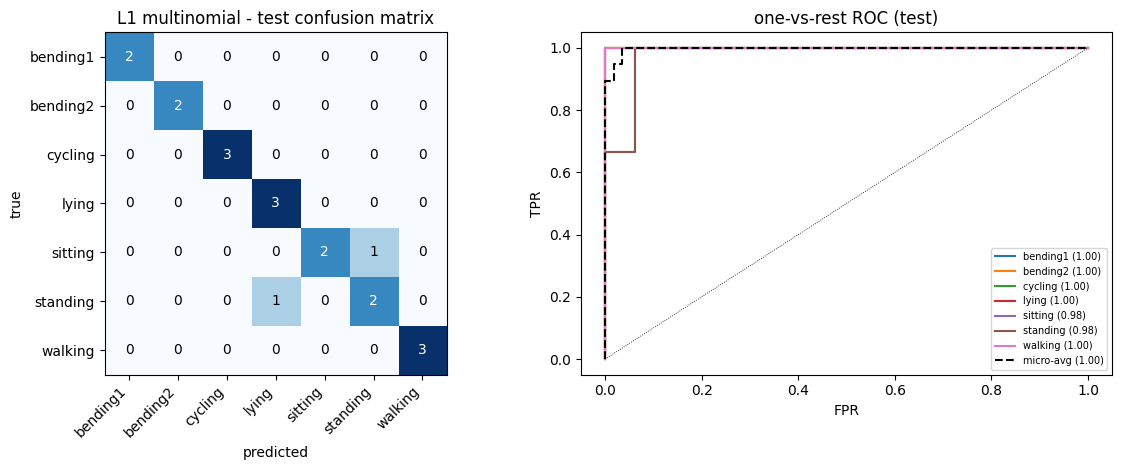

non-zero coef per class: [5 5 3 9 7 5 3] of 42
Gaussian NB: best CV acc 0.8557 at l=1;   CV acc by l: {1: 0.856, 2: 0.831, 3: 0.685, 4: 0.661, 5: 0.676, 6: 0.641, 7: 0.666, 8: 0.666, 9: 0.622, 10: 0.671, 11: 0.662, 12: 0.604, 13: 0.604, 14: 0.536, 15: 0.585, 16: 0.571, 17: 0.566, 18: 0.522, 19: 0.556, 20: 0.536}
Multinomial NB: best CV acc 0.8412 at l=1;   CV acc by l: {1: 0.841, 2: 0.798, 3: 0.788, 4: 0.792, 5: 0.826, 6: 0.797, 7: 0.812, 8: 0.816, 9: 0.797, 10: 0.807, 11: 0.797, 12: 0.788, 13: 0.792, 14: 0.788, 15: 0.782, 16: 0.773, 17: 0.787, 18: 0.783, 19: 0.788, 20: 0.763}

=== Gaussian NB (l=1): train error=0.0000  TEST ERROR=0.1053
test confusion matrix (rows=true, cols=pred), order ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 2 1 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]
one-vs-rest test AUC per class: {'bending1': 1.0, 'bending2': 1.0, 'cycling': 1.0, 'lying': 0.802, 'sit

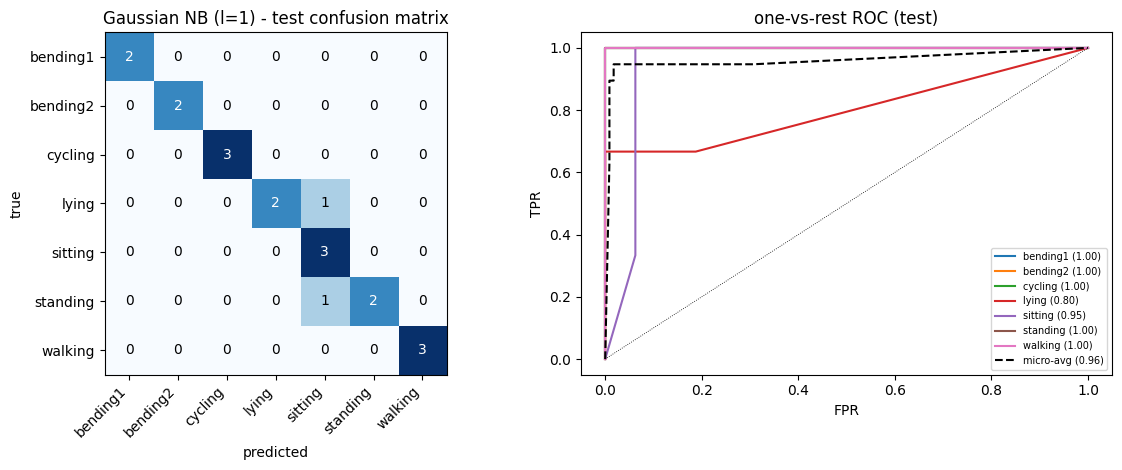


=== Multinomial NB (l=1): train error=0.0725  TEST ERROR=0.1053
test confusion matrix (rows=true, cols=pred), order ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]
one-vs-rest test AUC per class: {'bending1': 1.0, 'bending2': 1.0, 'cycling': 1.0, 'lying': 1.0, 'sitting': 0.958, 'standing': 0.938, 'walking': 1.0} | macro=0.985 micro=0.993


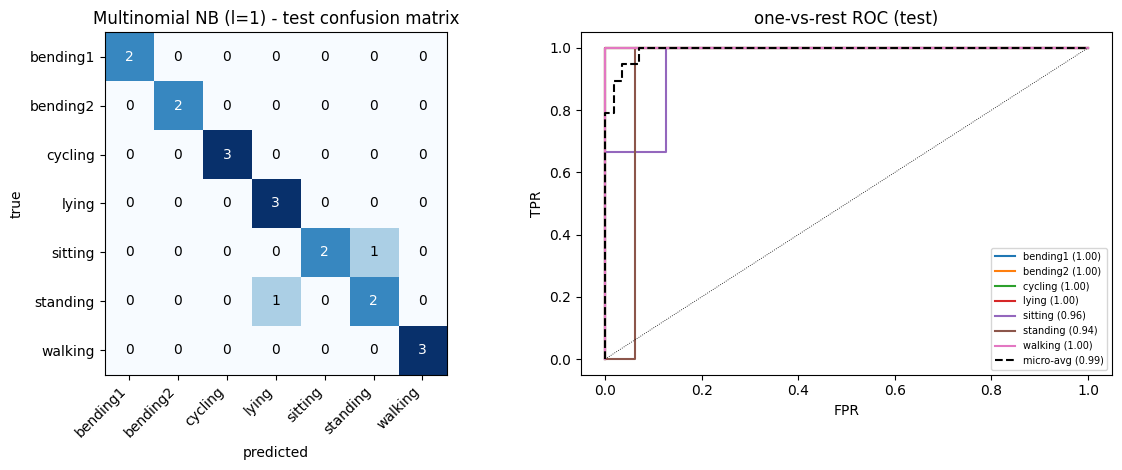


TEST ERROR summary: L1-multinomial=0.1053, GaussianNB=0.1053, MultinomialNB=0.1053


In [9]:
classes = ACTIVITIES; cidx = {c: i for i, c in enumerate(classes)}
ytr7 = np.array([cidx[a] for a in y_tr_act]); yte7 = np.array([cidx[a] for a in y_te_act])
print('train class counts', dict(zip(classes, np.bincount(ytr7)))); print('test class counts', dict(zip(classes, np.bincount(yte7))))
cv5 = RepeatedStratifiedKFold(n_splits=4, n_repeats=3, random_state=RNG_SEED)   
C7 = np.logspace(-1.5, 1.5, 7)
mn_results = {}
t0 = time.time()
for l in L_GRID:
    Xl = build_X(train, l).values
    pipe = Pipeline([('sc', StandardScaler()), ('lr', l1_lr(1.0, solver='saga', tol=1e-3, max_iter=500))])
    gs = GridSearchCV(pipe, {'lr__C': C7}, cv=cv5, scoring='accuracy').fit(Xl, ytr7)
    mn_results[l] = (gs.best_score_, gs.best_params_['lr__C'])
print('multinomial CV time', round(time.time() - t0, 1), 's')
print(pd.DataFrame(mn_results, index=['cv_acc', 'best_C']).T.round(4).to_string())
mn_best = max(v[0] for v in mn_results.values())
mn_l = min(l for l, v in mn_results.items() if abs(v[0] - mn_best) < 1e-12); mn_C = mn_results[mn_l][1]
print('best multinomial CV acc %.4f at l=%d, C=%.4g' % (mn_best, mn_l, mn_C))
sc_mn = StandardScaler().fit(build_X(train, mn_l).values)
Xtr_mn = sc_mn.transform(build_X(train, mn_l).values); Xte_mn = sc_mn.transform(build_X(test, mn_l).values)
m_mn = l1_lr(mn_C, solver='saga', tol=1e-4, max_iter=2000).fit(Xtr_mn, ytr7)

def multiclass_report(name, model, Xtr, Xte, fname):
    ptr, pte = model.predict(Xtr), model.predict(Xte)
    prb_te = model.predict_proba(Xte)
    print(f'\n=== {name}: train error={1-accuracy_score(ytr7, ptr):.4f}  TEST ERROR={1-accuracy_score(yte7, pte):.4f}')
    cmt = confusion_matrix(yte7, pte, labels=range(7))
    print('test confusion matrix (rows=true, cols=pred), order', classes); print(cmt)
    Y = label_binarize(yte7, classes=range(7))
    auc_ovr = {c: roc_auc_score(Y[:, k], prb_te[:, k]) for k, c in enumerate(classes) if Y[:, k].sum() > 0}
    macro = roc_auc_score(Y, prb_te, average='macro'); micro = roc_auc_score(Y, prb_te, average='micro')
    print('one-vs-rest test AUC per class:', {k: round(v, 3) for k, v in auc_ovr.items()}, '| macro=%.3f micro=%.3f' % (macro, micro))
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
    im = axs[0].imshow(cmt, cmap='Blues'); axs[0].set_xticks(range(7)); axs[0].set_yticks(range(7))
    axs[0].set_xticklabels(classes, rotation=45, ha='right'); axs[0].set_yticklabels(classes)
    for i in range(7):
        for j in range(7): axs[0].text(j, i, cmt[i, j], ha='center', va='center', color='white' if cmt[i, j] > cmt.max()/2 else 'black')
    axs[0].set_xlabel('predicted'); axs[0].set_ylabel('true'); axs[0].set_title(name + ' - test confusion matrix')
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], prb_te[:, k]); axs[1].plot(fpr, tpr, label=f'{c} ({roc_auc_score(Y[:, k], prb_te[:, k]):.2f})')
    fm, tm, _ = roc_curve(Y.ravel(), prb_te.ravel()); axs[1].plot(fm, tm, 'k--', label=f'micro-avg ({micro:.2f})')
    axs[1].plot([0, 1], [0, 1], 'k:', lw=.6); axs[1].set_xlabel('FPR'); axs[1].set_ylabel('TPR'); axs[1].legend(fontsize=7); axs[1].set_title('one-vs-rest ROC (test)')
    plt.tight_layout(); plt.savefig(fname, dpi=130); plt.show()
    return 1 - accuracy_score(yte7, pte)
err_mn = multiclass_report('L1 multinomial', m_mn, Xtr_mn, Xte_mn, 'figs/multiclass_l1.png')
print('non-zero coef per class:', (m_mn.coef_ != 0).sum(axis=1), 'of', Xtr_mn.shape[1])


def cv_nb(make, l):
    X = build_X(train, l).values
    s = []
    for tr, va in cv5.split(X, ytr7):
        s.append(accuracy_score(ytr7[va], make().fit(X[tr], ytr7[tr]).predict(X[va])))
    return np.mean(s)
nb = {}
for name, make in [('Gaussian', GaussianNB), ('Multinomial', MultinomialNB)]:
    sc = {l: cv_nb(make, l) for l in L_GRID}
    b = max(sc.values()); l_b = min(l for l, v in sc.items() if abs(v - b) < 1e-12)
    nb[name] = (make, l_b, b)
    print(f'{name} NB: best CV acc {b:.4f} at l={l_b};   CV acc by l:', {k: round(v, 3) for k, v in sc.items()})
nb_err = {}
for name, (make, l_b, b) in nb.items():
    Xa, Xb = build_X(train, l_b).values, build_X(test, l_b).values
    mdl = make().fit(Xa, ytr7)
    nb_err[name] = multiclass_report(f'{name} NB (l={l_b})', mdl, Xa, Xb, f'figs/multiclass_nb_{name.lower()}.png')
print('\nTEST ERROR summary: L1-multinomial=%.4f, GaussianNB=%.4f, MultinomialNB=%.4f' % (err_mn, nb_err['Gaussian'], nb_err['Multinomial']))

Q2(c)ii and iii: Naive Bayes and comparison

I used both a Gaussian and a Multinomial Naive Bayes on the raw features, which are all non-negative, and chose l by the same kind of cross-validation. The results are in the output of the previous cell.

All three methods make 2 errors on the 19 test instances, a test error of 10.5%. The errors are always among sitting, standing and lying, which are similar low-movement postures, while bending1, bending2, cycling and walking are always classified correctly. The cross-validation separates the methods a bit more. The L1 multinomial model has the best CV accuracy (about 0.89, against 0.86 for Gaussian NB and 0.84 for Multinomial NB) and the best macro AUC (0.994, against 0.985 for Multinomial NB and 0.964 for Gaussian NB), and it uses only 3–9 of the 42 features per class. Gaussian NB has 0 training error, so it fits the training set most closely. Hence, L1-penalized multinomial regression is the best method here, but with only 19 test instances the test error alone cannot really tell the three apart. All three chose l = 1, so splitting the series into more parts did not help in the 7-class problem with so few instances.

Q3. ISLR 4.8.3

Here there is one predictor (p = 1) and K classes. The observations in class k come from a normal distribution with mean μ_k and variance σ_k², and the variance can differ between classes. With prior π_k, the Bayes classifier assigns x to the class with the largest

p_k(x) = π_k · (1/(√(2π) σ_k)) · exp(−(x − μ_k)² / (2σ_k²)) / Σ_l π_l · (1/(√(2π) σ_l)) · exp(−(x − μ_l)² / (2σ_l²)).

The denominator is the same for every class, so it does not change which class has the largest value. Taking the logarithm also keeps the ordering. So I can maximize

log π_k − log σ_k − log√(2π) − (x − μ_k)² / (2σ_k²).

The constant log√(2π) is the same for all classes and can be dropped. Expanding the square gives the discriminant

δ_k(x) = −x² / (2σ_k²) + x·μ_k / σ_k² − μ_k² / (2σ_k²) − log σ_k + log π_k.

The coefficient of x² is −1/(2σ_k²), and it depends on k when the variances differ between classes. So it does not cancel when the classes are compared, and δ_k(x) is a quadratic function of x. The Bayes classifier is therefore quadratic (not linear). If all classes had the same variance σ², the x² term would be the same for every class and would cancel in the comparison, and we would get the linear discriminant of LDA.



Q4. ISLR 4.8.7

The predictor X is last year's percent profit. For companies that issued a dividend (Yes), X has mean 10, and for companies that did not (No) it has mean 0. Both have variance 36 (standard deviation 6), X is normal within each class, and the prior is P(Yes) = 0.8, so P(No) = 0.2. By Bayes' theorem, for X = 4:

P(Yes | X = 4) = 0.8·exp(−(4−10)² / (2·36)) / [0.8·exp(−(4−10)² / (2·36)) + 0.2·exp(−(4−0)² / (2·36))].

The common factor 1/(√(2π)·6) cancels from the numerator and the denominator, so only the exponentials and the priors remain. The cell below evaluates it.

In [10]:
import math
num = 0.8 * math.exp(-(4 - 10) ** 2 / (2 * 36))
den = num + 0.2 * math.exp(-(4 - 0) ** 2 / (2 * 36))
print('P(Yes | X=4) =', round(num / den, 4))

P(Yes | X=4) = 0.7519


So the probability that a company issues a dividend this year, given that its percent profit was 4 last year, is about 0.752 (75.2%).



Q1 (feature creation) was the programming part of Homework 3 and is not submitted again, but the code is needed here, so I included it in the first cells. 

Q5 is extra practice and hence, I have not included its answer.